# Task: Integrate Langfuse with the CrewAI Lead Qualification System
#### Phase 3 - Module 8: AI Evaluation & Benchmarking
--------
Continue the Module 7 project by adding Langfuse tracing and basic output evaluation.

## 1. Import Libraries

In [1]:
import os
from dotenv import load_dotenv
from langfuse import get_client
from openinference.instrumentation.crewai import CrewAIInstrumentor

## 2. Load Langfuse Environment Variables

In [2]:
from pathlib import Path

m8_env_path = Path.cwd() / ".env"
if not m8_env_path.is_file():
    raise FileNotFoundError(f"Create your M8/.env file first: {m8_env_path}")

load_dotenv(dotenv_path=m8_env_path, override=True)
required_keys = ["LANGFUSE_PUBLIC_KEY2", "LANGFUSE_SECRET_KEY2", "LANGFUSE_BASE_URL2"]
missing = [key for key in required_keys if not os.getenv(key)]
if missing:
    raise ValueError(f"Missing Langfuse keys in M8/.env: {', '.join(missing)}")

print("New Langfuse project credentials loaded (values hidden).")


New Langfuse project credentials loaded (values hidden).


## 3. Initialize & Verify Langfuse Client

In [3]:
langfuse = get_client()

if langfuse.auth_check():
    print("Langfuse authentication successful!")
else:
    print("Langfuse authentication failed!")


Langfuse authentication successful!


## 4. Configure CrewAI Tracing

Set up tracing to record the CrewAI workflow and agent execution in Langfuse using OpenInference and OpenTelemetry.

In [4]:
import base64
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import BatchSpanProcessor
from opentelemetry.exporter.otlp.proto.http.trace_exporter import OTLPSpanExporter

credentials = f"{os.environ['LANGFUSE_PUBLIC_KEY2']}:{os.environ['LANGFUSE_SECRET_KEY2']}"
auth_token = base64.b64encode(credentials.encode()).decode()
endpoint = os.environ["LANGFUSE_BASE_URL2"].rstrip("/") + "/api/public/otel/v1/traces"

exporter = OTLPSpanExporter(endpoint=endpoint, headers={"Authorization": f"Basic {auth_token}"})
tracer_provider = TracerProvider()
tracer_provider.add_span_processor(BatchSpanProcessor(exporter))
CrewAIInstrumentor().instrument(tracer_provider=tracer_provider)
print("CrewAI tracing enabled: spans will go directly to Langfuse; no trace files needed.")


CrewAI tracing enabled: spans will go directly to Langfuse; no trace files needed.


## 5. Reuse the Module 7 Multi-Agent System

### 5.1 Load Module 7 Environment

In [5]:
from pathlib import Path

# Locate the existing Module 7 environment file
m7_env_path = Path.cwd().parent / "M7" / ".env"

if not m7_env_path.is_file():
    raise FileNotFoundError(
        f"Module 7 .env file not found: {m7_env_path}"
    )

# Load M7 credentials without overwriting M8 variables
load_dotenv(dotenv_path=m7_env_path, override=False)

# Verify required credentials without displaying their values
print("M7 environment located:", m7_env_path.name)
print("Module 7 environment loaded successfully!")

M7 environment located: .env
Module 7 environment loaded successfully!


### 5.2 Verify Local Ollama Model

Check that Ollama is running and `qwen2.5:3b` is installed before creating the agents.

In [6]:
import requests

OLLAMA_MODEL = "qwen2.5:3b"
OLLAMA_BASE_URL = "http://localhost:11434"

try:
    response = requests.get(f"{OLLAMA_BASE_URL}/api/tags", timeout=10)
    response.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError("Ollama is not reachable. Start Ollama and try again.") from exc

installed_models = [m.get("name") for m in response.json().get("models", [])]
print("Ollama Status:", response.status_code)
print("Available Models:", installed_models)
if OLLAMA_MODEL not in installed_models:
    raise RuntimeError(f"Model missing. Run: ollama pull {OLLAMA_MODEL}")
print("Local model is ready.")

Ollama Status: 200
Available Models: ['qwen2.5:3b']
Local model is ready.


### 5.3 Load the Original Agents and Tasks

Load the agents and tasks from Module 7 using Ollama as the LLM.

In [7]:
import json

# Locate the original Module 7 notebook
m7_notebook_path = Path.cwd().parent / "M7" / "MAS_task.ipynb"

if not m7_notebook_path.is_file():
    raise FileNotFoundError(
        f"Module 7 notebook not found: {m7_notebook_path}"
    )

# Read the original notebook without modifying it
with open(m7_notebook_path, "r", encoding="utf-8") as file:
    m7_notebook = json.load(file)

# Select only the setup and component definition cells
setup_cells = [2, 9, 11, 13, 15]

# Configure the local model BEFORE defining the Module 7 agents.
from crewai import LLM

llm = LLM(
    model=f"ollama/{OLLAMA_MODEL}",
    base_url=OLLAMA_BASE_URL,
    temperature=0.2,
    max_tokens=700,
)
selected_model = f"ollama/{OLLAMA_MODEL}"

# Keep this local run independent of external web-search requests.
USE_SERPER = False
SERPER_API_KEY = ""

# Retain the Module 7 memory configuration.
embedder_config = {"provider": "onnx", "config": {}}
def create_agent_memory():
    return Memory(embedder=embedder_config, llm=llm)

# These indices correspond to the verified Module 7 notebook structure.
setup_cells = [2, 9, 11, 13, 15]
for index in setup_cells:
    cell = m7_notebook["cells"][index]
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        exec(compile(source, f"M7_cell_{index}", "exec"), globals())

print("Module 7 agent and task definitions loaded.")

Libraries imported OK
Tools ready: Lead DB Lookup (Serper key not provided)
Tasks defined OK
Module 7 agent and task definitions loaded.


### 5.4 Create the Crew

Create a sequential Crew with the Researcher, Scoring, and Report Writer agents.

In [8]:
# Recreate the original Crew from Module 7
crew_cell = m7_notebook["cells"][17]

source = "".join(crew_cell["source"])

exec(
    compile(source, "M7_crew_definition", "exec"),
    globals()
)

# Verify the restored Crew
print("\nCrew:", type(crew).__name__)
print("Agents:", len(crew.agents))
print("Tasks:", len(crew.tasks))
print("Tracer Provider:", type(tracer_provider).__name__)
print("Agent models:", [str(a.llm.model) for a in crew.agents])


Crew created OK

Crew: Crew
Agents: 3
Tasks: 3
Tracer Provider: TracerProvider
Agent models: ['qwen2.5:3b', 'qwen2.5:3b', 'qwen2.5:3b']


In [9]:

for i, agent in enumerate(crew.agents, start=1):
    print(f"Agent {i}: {agent.role}")
    print("  LLM:", agent.llm.model)
    print("  Memory:", type(agent.memory).__name__ if agent.memory else "Disabled")


Agent 1: Researcher Agent
  LLM: qwen2.5:3b
  Memory: Memory
Agent 2: Scoring Agent
  LLM: qwen2.5:3b
  Memory: Memory
Agent 3: Report Writer Agent
  LLM: qwen2.5:3b
  Memory: Memory


In [10]:

for i, agent in enumerate(crew.agents, start=1):
    memory_llm = getattr(agent.memory, "llm", None)
    model = getattr(memory_llm, "model", None)

    print(f"Agent {i} Memory LLM:", model or "Not specified")


Agent 1 Memory LLM: qwen2.5:3b
Agent 2 Memory LLM: qwen2.5:3b
Agent 3 Memory LLM: qwen2.5:3b


## 6. Run CrewAI and Monitor Execution in Langfuse

Run the workflow to find and qualify healthcare leads in the United States, then export the execution traces to Langfuse.

In [11]:
import time

inputs = {"industry": "Healthcare", "country": "United States"}
start_time = time.perf_counter()
result = None
execution_status = "FAILED"
error_message = None

try:
    result = await crew.kickoff_async(inputs=inputs)
    execution_status = "SUCCESS"
except Exception as exc:
    error_message = str(exc)
    print("Workflow Error:", error_message[:1000])
finally:
    execution_time = time.perf_counter() - start_time
    flush_success = tracer_provider.force_flush(timeout_millis=30000)
    print("Execution Status:", execution_status)
    print(f"Execution Time: {execution_time:.2f} seconds")
    print("Trace Flush:", flush_success)

if result is not None:
    print("\nFinal Lead Qualification Report:\n")
    print(result)


╭──────────────────────────────────────────── ✨ Update Available ✨ ─────────────────────────────────────────────╮
│                                                                                                                 │
│  A new version of CrewAI is available!                                                                          │
│                                                                                                                 │
│  Current version: 1.15.21                                                                                       │
│  Latest version:  1.15.27                                                                                       │
│                                                                                                                 │
│  To update, run: uv sync --upgrade-package crewai                                                               │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 9a5577f9-1aea-4174-93cb-dd6ab40d2787                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: Find potential leads in the Healthcare sector in United States. Use the Lead Database Lookup tool to     │
│  identify matching companies. Research each identified lead using at most one concise web search per company.   │
│  Collect available information such as company size, annual budget, industry fit, and business needs. Prepare   │
│  a short personalized outreach message for each lead. Keep findings concise and do not invent missing           │
│  information.                                                                                                   │
│  ID: 99b01e80-c80d-4892-bb6e-60f314a737c6                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Researcher Agent                                                                                        │
│                                                                                                                 │
│  Task: Find potential leads in the Healthcare sector in United States. Use the Lead Database Lookup tool to     │
│  identify matching companies. Research each identified lead using at most one concise web search per company.   │
│  Collect available information such as company size, annual budget, industry fit, and business needs. Prepare   │
│  a short personalized outreach message for each lead. Keep findings concise and do not invent missing           │
│  information.                                                                                                   │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────── 🔧 Tool Execution Started (#1) ─────────────────────────────────────────╮
│                                                                                                                 │
│  Tool: lead_database_lookup                                                                                     │
│  Args: {'industry': 'Healthcare', 'country': 'United States'}                                                   │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

[CrewAIEventsBus] Warning: Event pairing mismatch. 'llm_call_failed' closed 'flow_started' (expected 
'llm_call_started')

╭───────────────────────────────────────────────── ❌ LLM Error ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  LLM Call Failed                                                                                                │
│  Error: OpenAI API call failed: Could not parse response content as the length limit was reached -              │
│  CompletionUsage(completion_tokens=700, prompt_tokens=817, total_tokens=1517, completion_tokens_details=None,   │
│  prompt_tokens_details=PromptTokensDetails(audio_tokens=None, cache_write_tokens=None, cached_tokens=4))        │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 9a5577f9-1aea-4174-93cb-dd6ab40d2787                                                                       │
│  Final Output: # Lead Qualification Report                                                                      │
│                                                                                                                 │
│  ## Identified Leads                                                                                            │
│                                                                                                                 │
│  ### 1. **MedTech Solutions**                                                                                   │
│  - **Company Name:** MedTech Solutions                                                                          │
│  - **Industry:** Healthcare                                                                                     │
│  - **Country:** United States                                                                                   │
│  - **Employees:** 250                                                                                           │
│  - **Annual Budget:** $200,000                                                                                  │
│  - **Notes:** Interested in AI patient triage and healthcare automation.                                        │
│  - **Personalized Outreach Message:** "I came across your company's focus on AI patient triage and healthcare   │
│  automation, which aligns perfectly with our innovative solutions. Could you spare some time to discuss how     │
│  our AI tools can further enhance your operations and improve patient outcomes?"                                │
│                                                                                                                 │
│  ### 2. **HealthPulse AI**                                                                                      │
│  - **Company Name:** HealthPulse AI                                                                             │
│  - **Industry:** Healthcare                                                                                     │
│  - **Country:** United States                                                                                   │
│  - **Employees:** 120                                                                                           │
│  - **Annual Budget:** $95,000                                                                                   │
│  - **Notes:** Looking for diagnostic assistant software.                                                        │
│  - **Personalized Outreach Message:** "I noticed your interest in diagnostic assistant software, which is a     │
│  key area we specialize in. Our diagnostic assistant software can significantly improve diagnostic accuracy     │
│  and efficiency. I would love to schedule a call to explore how we can help meet your needs."                   │
│                                                                                                                 │
│  ### 3. **BioCare Innovation**                                                                                  │
│  - **Company Name:** BioCare Innovation                                                                         │
│  - **Industry:** Healthcare                                                                                     │
│  - **Country:** United States                         

╭──────────────────────────────────────────────── Tracing Status ─────────────────────────────────────────────────╮
│                                                                                                                 │
│  Info: Tracing is disabled.                                                                                     │
│                                                                                                                 │
│  To enable tracing, do any one of these:                                                                        │
│  • Set tracing=True in your Crew/Flow code                                                                      │
│  • Set CREWAI_TRACING_ENABLED=true in your project's .env file                                                  │
│  • Run: crewai traces enable                                                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Execution Status: SUCCESS
Execution Time: 1281.42 seconds
Trace Flush: True

Final Lead Qualification Report:

# Lead Qualification Report

## Identified Leads

### 1. **MedTech Solutions**
- **Company Name:** MedTech Solutions
- **Industry:** Healthcare
- **Country:** United States
- **Employees:** 250
- **Annual Budget:** $200,000
- **Notes:** Interested in AI patient triage and healthcare automation.
- **Personalized Outreach Message:** "I came across your company's focus on AI patient triage and healthcare automation, which aligns perfectly with our innovative solutions. Could you spare some time to discuss how our AI tools can further enhance your operations and improve patient outcomes?"

### 2. **HealthPulse AI**
- **Company Name:** HealthPulse AI
- **Industry:** Healthcare
- **Country:** United States
- **Employees:** 120
- **Annual Budget:** $95,000
- **Notes:** Looking for diagnostic assistant software.
- **Personalized Outreach Message:** "I noticed your interest in diagnost

### 6.1 Langfuse Traces

The screenshots below show the recorded CrewAI workflow and the input and output of one task in Langfuse.

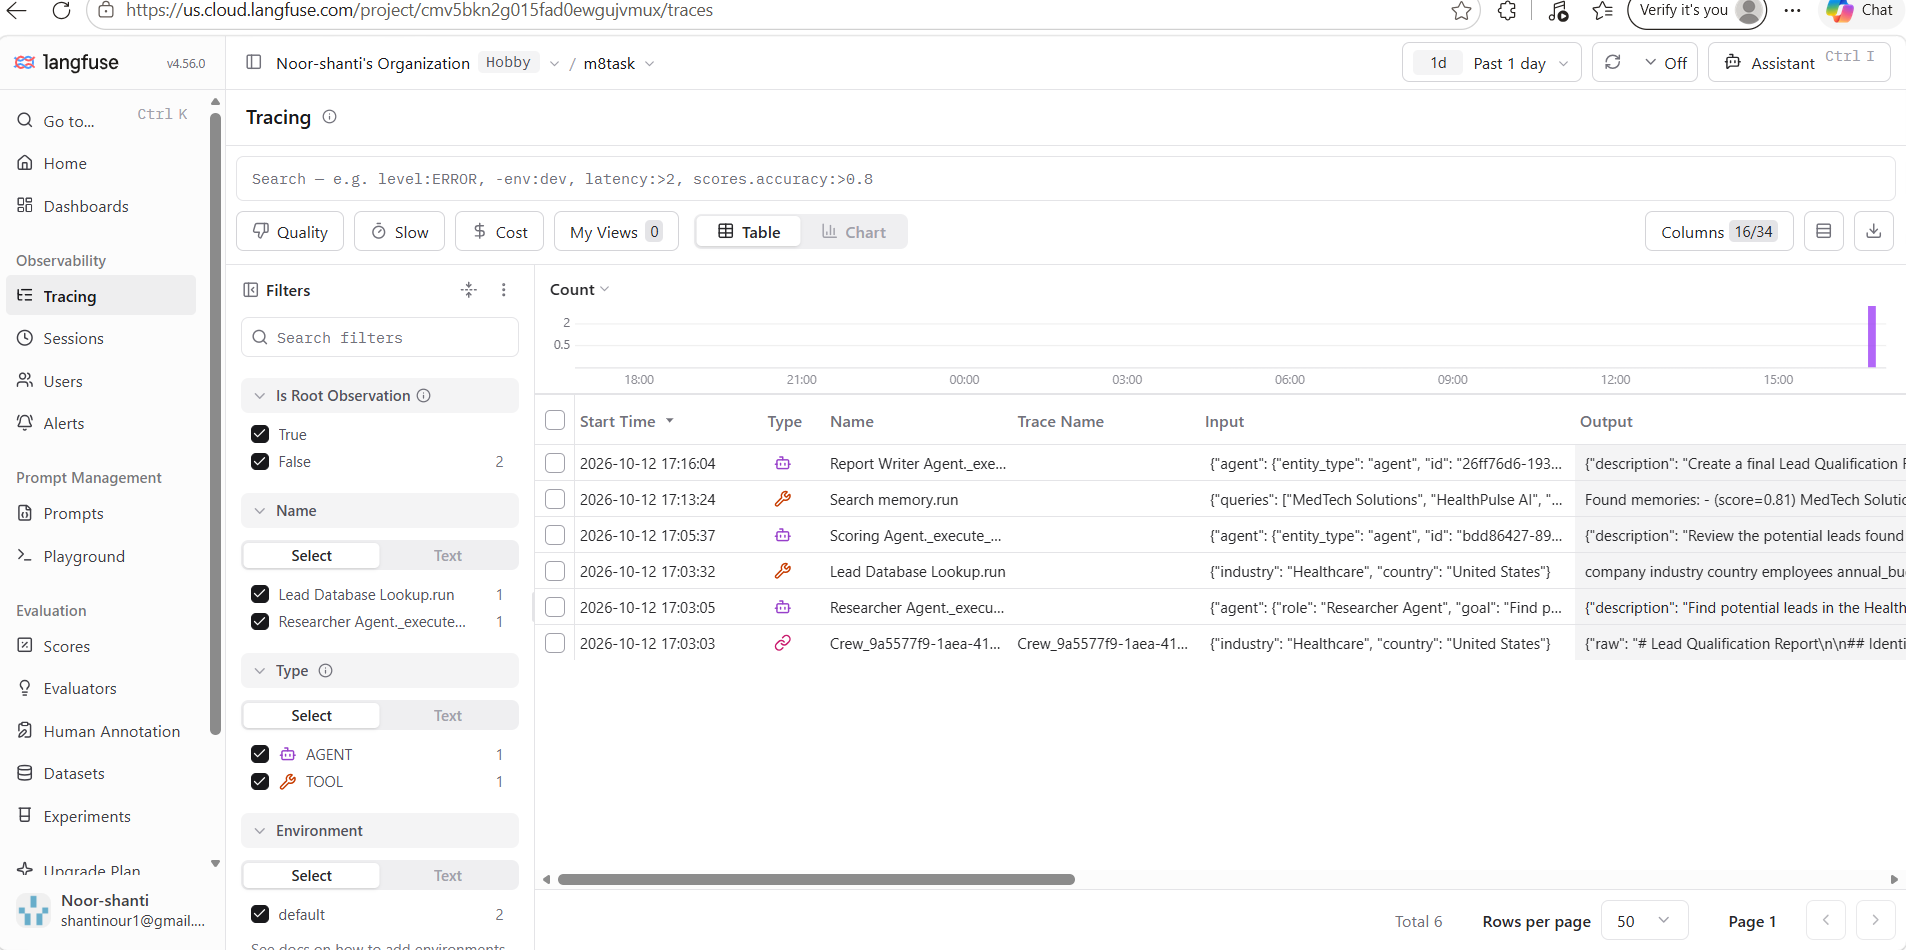


The workflow trace shows the three agents running sequentially, their tool calls, and the workflow input and output.

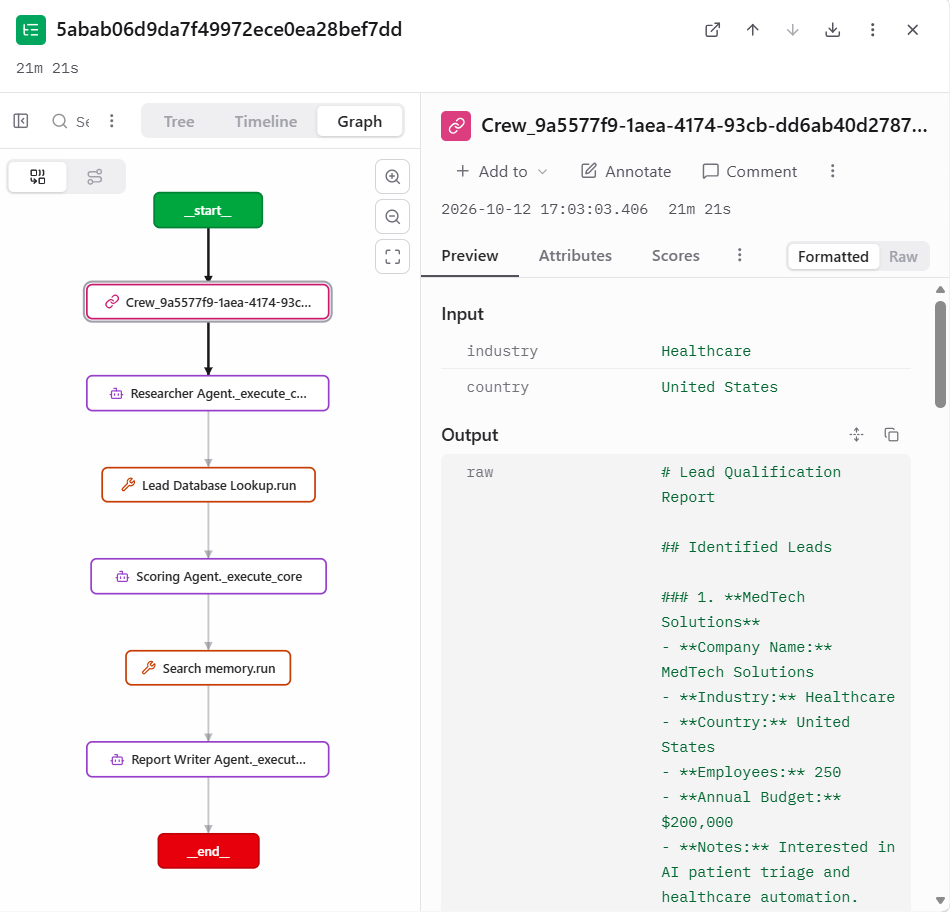

## 7. Evaluate the CrewAI Result

Check the generated report for lead consistency, complete scoring, correct totals, and matching priority labels.

In [ ]:
import re
import pandas as pd
from IPython.display import display

if "result" not in globals() or result is None:
    raise RuntimeError(
        "CrewAI result is not available in this kernel. "
        "Do not restart the kernel after Section 6."
    )

if len(result.tasks_output) < 2:
    raise RuntimeError("Expected Researcher and Scoring task outputs.")

research_output = str(result.tasks_output[0].raw)
scoring_output = str(result.tasks_output[1].raw)
final_report = str(result.raw)


# ============================================================
# HELPERS
# ============================================================

def normalize_name(name):
    name = re.sub(r"[*_`]", "", str(name))
    name = re.sub(r"\s+", " ", name)
    return name.strip(" :.-").casefold()


def clean_markdown(line):
    line = line.strip()
    line = re.sub(r"^\s*(?:[-*+]\s+)", "", line)
    line = line.replace("**", "").replace("__", "")
    return line.strip()


def get_field(body, label):
    """
    Handles:
    - **Total Score:** 207
    - Total Score: 207
    - **Priority:** High
    """
    for line in body.splitlines():
        cleaned = clean_markdown(line)
        match = re.match(
            rf"^{re.escape(label)}\s*:\s*(.*)$",
            cleaned,
            flags=re.I
        )
        if match:
            return match.group(1).strip()
    return None


def get_number(value):
    if value is None:
        return None

    match = re.search(r"-?\d+(?:\.\d+)?", str(value))
    return float(match.group()) if match else None


def get_priority(value):
    if value is None:
        return None

    match = re.search(
        r"\b(High|Medium|Low)\b",
        str(value),
        flags=re.I
    )
    return match.group(1).title() if match else None


def get_subscore(body, labels):
    """
    Extracts explicit component scores.
    Does not invent missing values.
    """
    for label in labels:
        value = get_field(body, label)

        if value is None:
            continue

        match = re.search(
            r"\(\s*Score\s*:\s*(-?\d+(?:\.\d+)?)\s*\)",
            value,
            flags=re.I
        )
        if match:
            return float(match.group(1))

        match = re.match(
            r"^\s*(-?\d+(?:\.\d+)?)\s*(?:/\s*\d+)?\s*$",
            value
        )
        if match:
            return float(match.group(1))

    return None


def extract_headings(text):
    pattern = (
        r"(?m)^#{2,5}\s*"
        r"(?:Lead\s*)?\d+\s*[.):]\s*"
        r"(.+?)\s*$"
    )

    return [
        normalize_name(match)
        for match in re.findall(pattern, text)
    ]


def extract_company_fields(text):
    """
    Finds company names in Markdown fields.
    """
    names = []

    for line in text.splitlines():
        cleaned = clean_markdown(line)

        match = re.match(
            r"^(?:Company Name|Company)\s*:\s*(.+)$",
            cleaned,
            flags=re.I
        )

        if match:
            names.append(normalize_name(match.group(1)))

    return names


def unique_names(names):
    return list(dict.fromkeys(
        name for name in names if name
    ))


def extract_sections(text, section_title=None):
    if section_title:
        match = re.search(
            rf"(?im)^##\s*{re.escape(section_title)}\s*$",
            text
        )
        if match:
            text = text[match.end():]

    pattern = (
        r"(?m)^#{2,5}\s*"
        r"(?:Lead\s*)?\d+\s*[.):]\s*"
        r"(.+?)\s*$"
    )

    matches = list(re.finditer(pattern, text))
    sections = []

    for i, match in enumerate(matches):
        end = (
            matches[i + 1].start()
            if i + 1 < len(matches)
            else len(text)
        )

        name = normalize_name(match.group(1))
        body = text[match.end():end]

        sections.append((name, body))

    return sections


# ============================================================
# 1. LEAD CONSISTENCY
# ============================================================

research_names = set(unique_names(
    extract_headings(research_output)
    + extract_company_fields(research_output)
))

identified_leads = re.split(
    r"(?im)^##\s*Lead Qualification Scores\s*$",
    final_report,
    maxsplit=1
)[0]

report_names = unique_names(
    extract_headings(identified_leads)
    + extract_company_fields(identified_leads)
)

# Use the report's numbered headings as the main lead list
heading_names = unique_names(extract_headings(identified_leads))

if heading_names:
    report_names = heading_names

lead_rows = []

for name in report_names:
    lead_rows.append({
        "Lead": name,
        "Found in Researcher Output": name in research_names
    })

lead_checks = pd.DataFrame(
    lead_rows,
    columns=["Lead", "Found in Researcher Output"]
)

print("=" * 55)
print("1. LEAD CONSISTENCY")
print("=" * 55)

display(lead_checks)

if lead_checks.empty or not research_names:
    lead_consistency = None
    print("Lead Consistency: NOT MEASURABLE")
    print("Researcher names could not be reliably extracted.")
else:
    lead_consistency = (
        lead_checks["Found in Researcher Output"].mean()
    )
    print(f"Lead Consistency: {lead_consistency:.1%}")


# ============================================================
# 2. SCORING EVALUATION
# ============================================================

sections = extract_sections(
    final_report,
    section_title="Lead Qualification Scores"
)

# If the final report has no scoring sections,
# inspect the Scoring Agent's output instead.
if not sections:
    sections = extract_sections(scoring_output)

rows = []

for name, body in sections:

    budget = get_subscore(body, ["Budget"])
    need = get_subscore(body, ["Need", "Business Need"])
    fit = get_subscore(body, ["Company Fit", "Fit"])
    timeline = get_subscore(body, ["Timeline"])

    subscores = [budget, need, fit, timeline]

    reported_total = get_number(
        get_field(body, "Total Score")
    )

    if reported_total is None:
        reported_total = get_number(
            get_field(body, "Overall Score")
        )

    reported_priority = get_priority(
        get_field(body, "Priority")
    )

    complete_subscores = all(
        value is not None for value in subscores
    )

    calculated_sum = (
        round(sum(subscores), 4)
        if complete_subscores
        else None
    )

    decimal_scale = (
        complete_subscores
        and all(0 <= value <= 1 for value in subscores)
    )

    arithmetic_correct = (
        calculated_sum is not None
        and reported_total is not None
        and abs(calculated_sum - reported_total) < 0.01
    )

    total_valid = (
        reported_total is not None
        and 0 <= reported_total <= 100
    )

    expected_priority = None

    if total_valid:
        expected_priority = (
            "High" if reported_total >= 70
            else "Medium" if reported_total >= 40
            else "Low"
        )

    priority_correct = (
        expected_priority is not None
        and reported_priority == expected_priority
    )

    scoring_complete = (
        complete_subscores
        and reported_total is not None
        and reported_priority is not None
    )

    rows.append({
        "Lead": name,
        "Budget": budget,
        "Need": need,
        "Company Fit": fit,
        "Timeline": timeline,
        "Calculated Sum": calculated_sum,
        "Reported Total": reported_total,
        "Reported Priority": reported_priority,
        "Expected Priority": expected_priority,
        "Complete Scoring": bool(scoring_complete),
        "Decimal Scale Detected": bool(decimal_scale),
        "Arithmetic Correct": bool(arithmetic_correct),
        "Total Within 0-100": bool(total_valid),
        "Priority Correct": bool(priority_correct)
    })

checks = pd.DataFrame(rows)

print("\n" + "=" * 55)
print("2. SCORING EVALUATION")
print("=" * 55)

display(checks)


# ============================================================
# 3. AUTOMATED EVALUATION SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("3. AUTOMATED EVALUATION SUMMARY")
print("=" * 55)

summary_rows = []

summary_rows.append({
    "Metric": "Lead Consistency",
    "Score": lead_consistency,
    "Status": (
        "Measured"
        if lead_consistency is not None
        else "Not Measurable"
    )
})

metrics = {
    "Scoring Completeness": "Complete Scoring",
    "Arithmetic Consistency": "Arithmetic Correct",
    "Total Range Validity": "Total Within 0-100",
    "Priority Consistency": "Priority Correct"
}

for metric_name, column in metrics.items():
    if checks.empty:
        score = None
    else:
        score = float(checks[column].mean())

    summary_rows.append({
        "Metric": metric_name,
        "Score": score,
        "Status": (
            "Measured"
            if score is not None
            else "Not Measurable"
        )
    })

summary = pd.DataFrame(summary_rows)

summary["Score"] = summary["Score"].apply(
    lambda value: (
        f"{value:.1%}"
        if pd.notna(value)
        else "N/A"
    )
)

display(summary)


# ============================================================
# 4. FINDINGS
# ============================================================

print("\n4. EVALUATION FINDINGS")

if checks.empty:
    print("- No scoring sections could be extracted.")
else:
    invalid_totals = int(
        (~checks["Total Within 0-100"]).sum()
    )

    arithmetic_errors = int(
        (~checks["Arithmetic Correct"]).sum()
    )

    incomplete = int(
        (~checks["Complete Scoring"]).sum()
    )

    decimal_cases = int(
        checks["Decimal Scale Detected"].sum()
    )

    print(f"- Leads evaluated: {len(checks)}")
    print(f"- Incomplete scoring records: {incomplete}")
    print(f"- Invalid or missing totals: {invalid_totals}")
    print(f"- Arithmetic inconsistencies: {arithmetic_errors}")
    print(f"- Decimal-scale scoring cases: {decimal_cases}")

print("\nEvaluation completed.")
print("No trace JSON files were used.")
print("No CrewAI agents were executed again.")
print(
    "Note: These are rule-based consistency checks, "
    "not independent factual verification."
)


1. LEAD CONSISTENCY


,Lead,Found in Researcher Output
0,medtech solutions,True
1,healthpulse ai,True
2,biocare innovation,True


Lead Consistency: 100.0%

2. SCORING EVALUATION


,Lead,Budget,Need,Company Fit,Timeline,Calculated Sum,Reported Total,Reported Priority,Expected Priority,Complete Scoring,Decimal Scale Detected,Arithmetic Correct,Total Within 0-100,Priority Correct
0,medtech solutions,0.81,0.75,0.71,0.69,2.96,207.0,High,None,True,True,False,False,False
1,healthpulse ai,0.71,0.77,0.71,0.69,2.88,206.0,High,None,True,True,False,False,False
2,biocare innovation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,False,False,False,False,False



3. AUTOMATED EVALUATION SUMMARY


,Metric,Score,Status
0,Lead Consistency,100.0%,Measured
1,Scoring Completeness,66.7%,Measured
2,Arithmetic Consistency,0.0%,Measured
3,Total Range Validity,0.0%,Measured
4,Priority Consistency,0.0%,Measured



4. EVALUATION FINDINGS
- Leads evaluated: 3
- Incomplete scoring records: 1
- Invalid or missing totals: 3
- Arithmetic inconsistencies: 3
- Decimal-scale scoring cases: 2

Evaluation completed.
No trace JSON files were used.
No CrewAI agents were executed again.
Note: These are rule-based consistency checks, not independent factual verification.


### 7.1 Evaluation Findings and What I Learned

The evaluation of this run produced the following results:

| Check | Result |
| --- | --- |
| Lead Consistency | 100% |
| Scoring Completeness | 66.7% |
| Arithmetic Consistency | 0% |
| Total Range Validity | 0% |
| Priority Consistency | 0% |

All three lead names in the final report appeared in the Researcher output. However, the scoring did not follow the required rubric. MedTech Solutions and HealthPulse AI received totals of 207 and 206, above the maximum of 100. Their component scores used a different scale, and their totals did not match the component sums. The scoring section for BioCare Innovation was incomplete.

The report also assigned a Timeline score even though no timeline was provided. This showed me that checking arithmetic alone is not enough; scores should also be supported by the available information.

Through this experiment, I learned the difference between tracing and evaluation. Langfuse helps me inspect the workflow execution, while the evaluation checks whether the generated report meets specific requirements. The workflow completed successfully, but its output still contained errors. Providing a scoring rubric in the prompt does not guarantee that the agents will follow it.

### 7.2 Evaluation Limitations and Possible Improvements

These are basic rule-based checks applied to one run. They check report consistency but do not verify company facts or assess the quality of the outreach messages. A 100% lead consistency score only confirms that the reported names appeared in the Researcher output.

The checks depend on the report's Markdown format. Missing or incomplete fields fail the relevant checks, so a failed arithmetic check can mean either an incorrect sum or insufficient information to check it. The evaluator checks that totals fall within 0–100, but it does not validate the individual limits for Budget, Need, Company Fit, and Timeline.

The evaluation results are displayed in the notebook and are not uploaded to Langfuse. Since this experiment covers only one run, it is not a benchmark of the system's overall performance.

To improve the evaluation, I would use a structured output format, validate each component against the scoring rubric, and repeat the experiment with different inputs. This would help distinguish recurring agent errors from problems caused by the output format.